## Black-hole binary formation channels with gaussian mixtures.
Some events form in different astrophysical environments than others. You want to figure out how many of formation channels are at play.

The strategy here is to fit a Gaussian Mixture model: that is, my model is a sum of N gaussians each with mean $\mu_j$ and standard deviation $\sigma_j$
 and weight $\alpha_j$:

 $$p(x_i|\theta) = \sum_{i=1}^N \alpha_j \mathcal{N}(\mu_j, \sigma_j)$$


This depends on $3N - 1$ parameters (not $3N$ because the sum of the $\alpha_j$ must be unity to ensure that this is a probability).

The dataset contains the masses of BH binaries.

### Tasks
- Load this file (np.load) and complete a quick exploration of the data. How many modes do you think you see?
- We'll use sklearn.mixture.GaussianMixture. You first need to define the model (instance of a class), and then train it on the data using the fit method (the data provided are already in the right numpy format!). This will output the trained model, which has various attributes.

${Note}$ We'll do a more formal introduction to scikit-learn in one of the next lectures. Today's exercise is meant to be a formative example on how you might find yourself dealing with a library you've never seen before. This happens all the time in research...

- Complete the fit 10 times with $N = 1,...,10$ Gaussians.
  
$Note$: sklearn by default will use the so-called Expectation-Maximization algorithm, which is one of the many great things in data science we don't have time to study in this class.

- For each of this fits, compute the AIC (easy! It's an attribute of the trained model!). Plot $N$ vs AIC: which model is preferred?
- Plot the preferred solution on top of the input data. You should get a very nice fit!

In [1]:
import numpy as np
from matplotlib import pyplot as plt


file_path = 'formationchannels.npy'
data = np.load(file_path)

N=3000
set_x = np.linspace(-10,50, N)

print(f"The \"shape\" of the data set is: {data.shape}")

The "shape" of the data set is: (2950, 1)


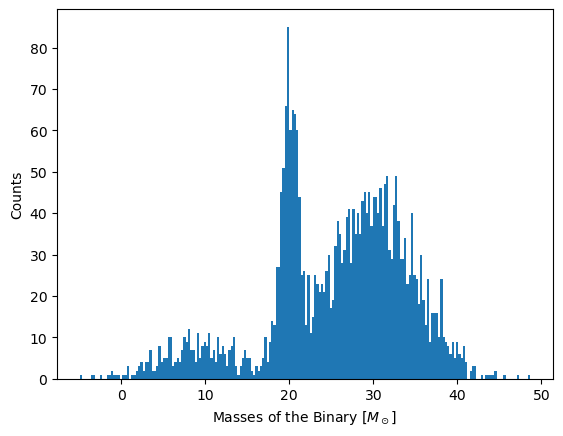

In [2]:
plt.hist(data, bins = 200)
plt.ylabel("Counts")
plt.xlabel(r"Masses of the Binary [$M_\odot$]")
plt.show()

Negative masses?

### Gaussian Mixture

In [3]:
from sklearn.mixture import GaussianMixture as gm

def likelihood(x, mu, sigma):
    norm = 1/np.sqrt(2 * np.pi * sigma**2)
    exp = np.exp(-(x - mu)**2/(2*sigma**2))
    p = norm * exp
    return p

In [4]:
n = np.linspace(1, 10, num = 10)
print(n)

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]


#### Test
Try with 3 gaussians

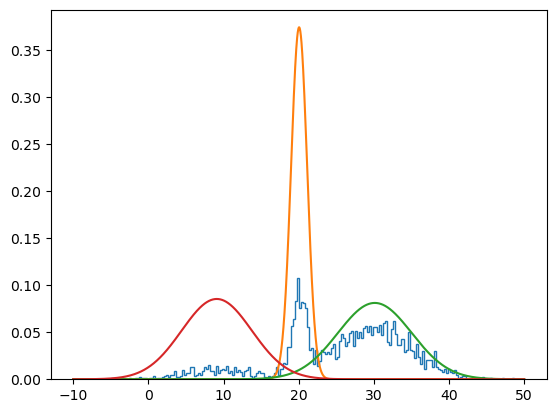

In [5]:
gm1 = gm(3).fit(data)

gaussians = np.array([likelihood(set_x, mu_i, np.sqrt(sigma_i)) for mu_i, sigma_i in zip(gm1.means_.ravel(), gm1.covariances_.ravel())])

plt.hist(data, bins = 200, histtype = 'step', density = True)
plt.plot(set_x, gaussians.T)
plt.show()

#### General Scenario

In [6]:
gms = np.array([gm(int(i)).fit(data) for i in n])
many_gaus = []

for gmi in gms:
    plot = np.array([likelihood(set_x, mu_i, np.sqrt(sigma_i)) for mu_i, sigma_i in zip(gmi.means_.ravel(), gmi.covariances_.ravel())])
    many_gaus.append(plot)

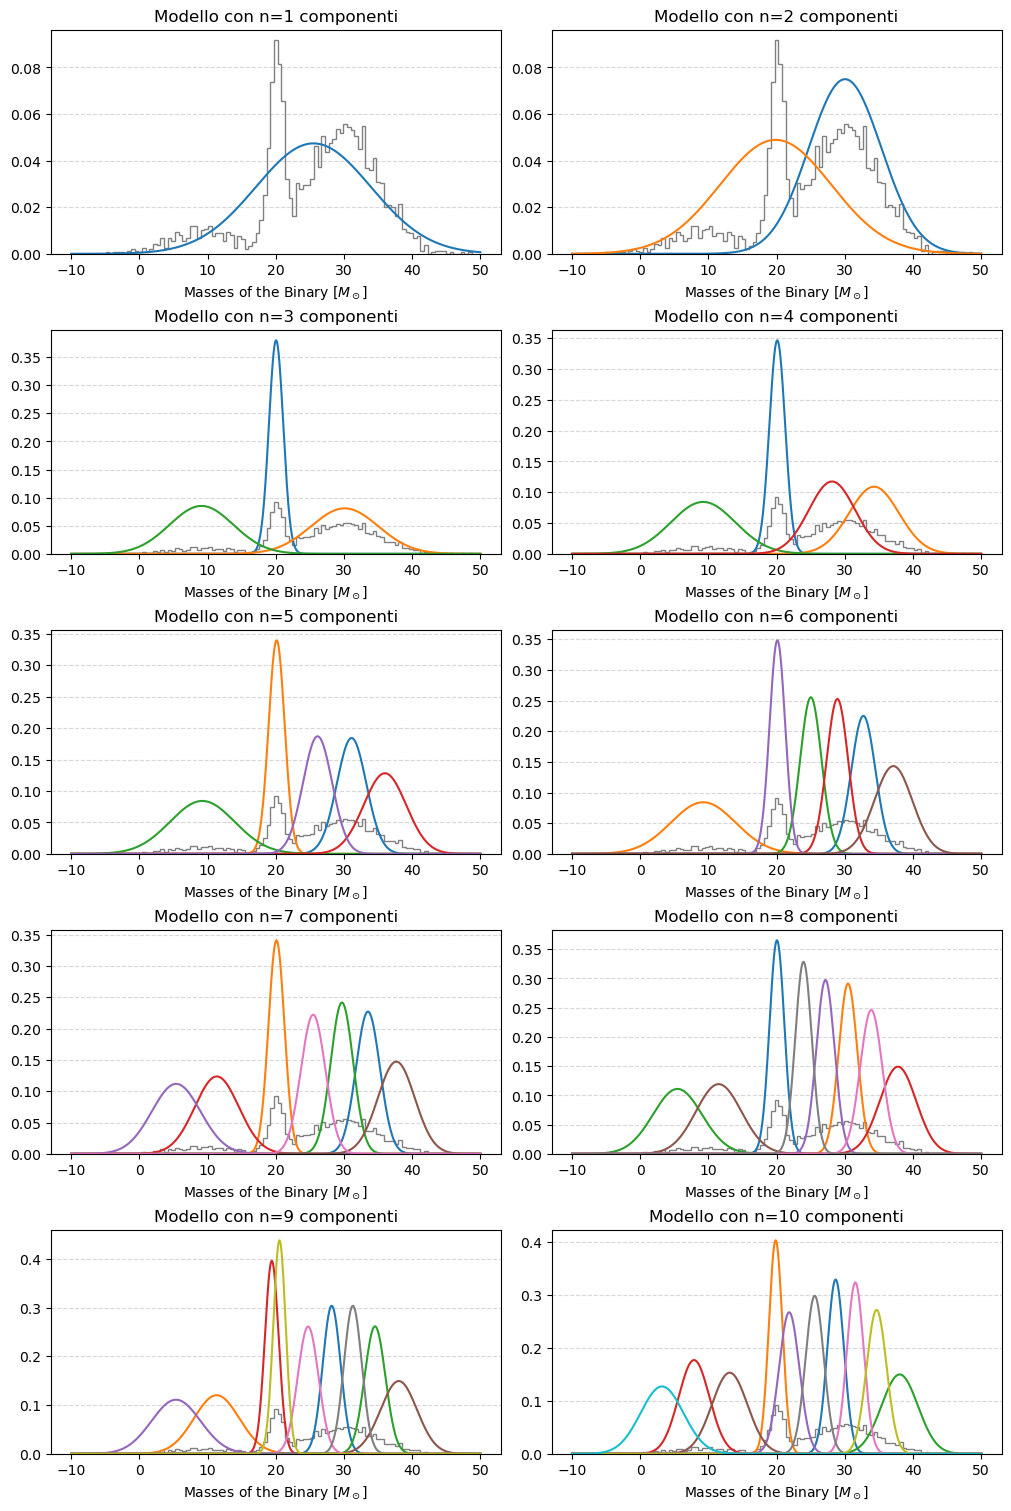

In [25]:
fig, axes = plt.subplots(5, 2, figsize=(10, 15), constrained_layout=True)
axes = axes.flatten() # Trasformiamo la matrice di assi in una lista piatta per iterare facilmente

for i, gaus_model in enumerate(many_gaus):
    ax = axes[i]
    
    # 1. Plot istogramma sui dati (sullo sfondo di ogni subplot)
    ax.hist(data, bins=100, histtype='step', density=True, color='gray')
    
    # 2. Plot delle singole gaussiane del modello i-esimo
    ax.plot(set_x, gaus_model.T)
    
    ax.set_title(f"Modello con n={int(n[i])} componenti")
    ax.set_xlabel(r"Masses of the Binary [$M_\odot$]")
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

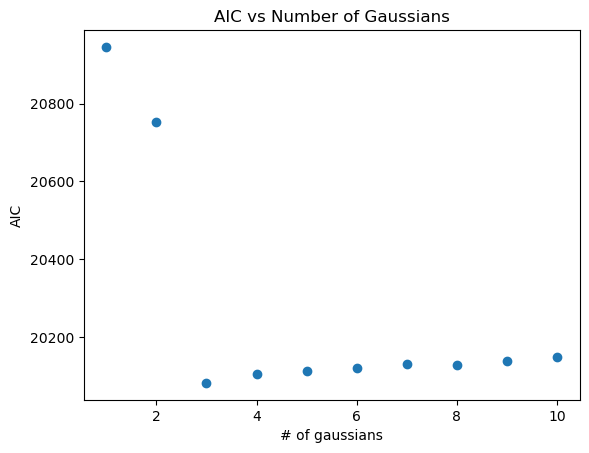

In [23]:
aics = np.array([gmi.aic(data) for gmi in gms])

plt.scatter(n, aics)
plt.title("AIC vs Number of Gaussians")
plt.ylabel("AIC")
plt.xlabel("# of gaussians")
plt.show()